# 03 — Modelagem e Avaliação
**CRISP-DM — etapas 4 e 5.** Treinamos 5 modelos com a mesma interface (perfil → ranking de jogos), ajustamos
hiperparâmetros num conjunto de **validação** e reportamos o resultado num conjunto de **teste** separado.

| Modelo | Tipo | Por que entra |
|---|---|---|
| Popularidade | baseline | qualquer modelo precisa superar "recomendar o mais popular" |
| Conteúdo TF-IDF (média / máximo) | baseado em conteúdo | proposta original do seminário |
| Colaborativo item-item | filtragem colaborativa | usa o comportamento real dos usuários (base B) |
| Fatoração SVD | fatoração de matriz | captura padrões latentes de gosto |
| Híbrido | conteúdo + colaborativo | une as duas fontes de informação |

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config, carregamento as c, preparacao as p, graficos as g

config.criar_pastas()
g.aplicar_estilo()
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
print("Percentual de usuários amostrados:", config.PERCENTUAL_USUARIOS, "%")

import time
import joblib
from src import modelos as m, avaliacao as av

Percentual de usuários amostrados: 15 %


In [2]:
catalogo = pd.read_parquet(config.ARQ_CATALOGO)
treino = pd.read_parquet(config.ARQ_TREINO)
teste = pd.read_parquet(config.ARQ_TESTE)

indice = m.IndiceCatalogo(catalogo)
matriz_ui = m.matriz_usuario_item(treino, indice)
casos = av.montar_casos(treino, teste, indice, n_usuarios=config.N_USUARIOS_AVALIACAO)
validacao, casos_teste = av.separar_validacao(casos)

densidade = matriz_ui.nnz / (matriz_ui.shape[0] * matriz_ui.shape[1])
print(f"Matriz usuário x jogo: {matriz_ui.shape} | densidade {densidade:.4%}")
print(f"Usuários avaliados: {len(casos):,} (validação {len(validacao):,} | teste {len(casos_teste):,})")

Matriz usuário x jogo: (116305, 15451) | densidade 0.0883%
Usuários avaliados: 5,000 (validação 1,500 | teste 3,500)


## Treinamento

In [3]:
tempos = {}
def treinar(nome, fabrica):
    t = time.time()
    modelo = fabrica()
    tempos[nome] = time.time() - t
    print(f"{nome:<32} treinado em {tempos[nome]:.1f}s")
    return modelo

pop = treinar("Popularidade", lambda: m.Popularidade(indice, treino))
tfidf_media = treinar("Conteúdo TF-IDF (média)", lambda: m.ConteudoTFIDF(indice, "media"))
tfidf_max = treinar("Conteúdo TF-IDF (máximo)", lambda: m.ConteudoTFIDF(indice, "maximo"))
item_item = treinar("Colaborativo item-item", lambda: m.ColaborativoItemItem(indice, matriz_ui))
print(f"Vocabulário TF-IDF: {len(tfidf_media.vetorizador.vocabulary_):,} tokens")

Popularidade                     treinado em 0.1s


Conteúdo TF-IDF (média)          treinado em 0.3s


Conteúdo TF-IDF (máximo)         treinado em 0.2s


Colaborativo item-item           treinado em 6.0s
Vocabulário TF-IDF: 510 tokens


## Ajuste de hiperparâmetros na validação (perfil de 5 jogos)

### SVD — número de dimensões latentes

In [4]:
grade_svd = []
for d in [16, 32, 64, 128]:
    if d >= min(matriz_ui.shape):
        continue
    modelo = m.FatoracaoSVD(indice, matriz_ui, n_componentes=d)
    _, r = av.avaliar(modelo, validacao, tamanho_perfil=5)
    grade_svd.append({"dimensoes": d, "ndcg@10": r["ndcg@10"]})
grade_svd = pd.DataFrame(grade_svd)
melhor_d = int(grade_svd.loc[grade_svd["ndcg@10"].idxmax(), "dimensoes"])
svd = treinar("Fatoração SVD", lambda: m.FatoracaoSVD(indice, matriz_ui, n_componentes=melhor_d))
grade_svd

Fatoração SVD                    treinado em 0.8s


,dimensoes,ndcg@10
0,16,0.0390
1,32,0.0344
2,64,0.0325
3,128,0.0321


### Híbrido — peso α do conteúdo (α = 0 → só colaborativo; α = 1 → só conteúdo)

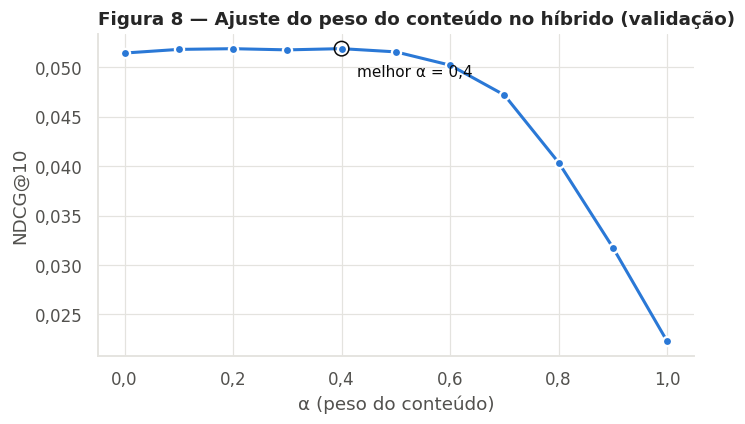

,alpha,ndcg@10,hit_rate@10
0,0.0000,0.0514,0.1853
1,0.1000,0.0518,0.1860
2,0.2000,0.0519,0.1840
3,0.3000,0.0518,0.1880
4,0.4000,0.0519,0.1893
5,0.5000,0.0516,0.1893
6,0.6000,0.0502,0.1867
7,0.7000,0.0472,0.1740
8,0.8000,0.0404,0.1507
9,0.9000,0.0318,0.1180


In [5]:
grade_alpha = []
for alpha in np.round(np.arange(0, 1.01, 0.1), 1):
    h = m.Hibrido(indice, tfidf_media, item_item, peso_conteudo=alpha)
    _, r = av.avaliar(h, validacao, tamanho_perfil=5)
    grade_alpha.append({"alpha": alpha, "ndcg@10": r["ndcg@10"], "hit_rate@10": r["hit_rate@10"]})
grade_alpha = pd.DataFrame(grade_alpha)
melhor_alpha = float(grade_alpha.loc[grade_alpha["ndcg@10"].idxmax(), "alpha"])
hibrido = m.Hibrido(indice, tfidf_media, item_item, peso_conteudo=melhor_alpha)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(grade_alpha["alpha"], grade_alpha["ndcg@10"], color=g.AZUL, marker="o", markersize=6,
        markeredgecolor="white", markeredgewidth=1.5)
ax.scatter([melhor_alpha], [grade_alpha["ndcg@10"].max()], s=90, facecolor="none", edgecolor=g.TEXTO, zorder=4)
ax.annotate(f"melhor α = {g.br(melhor_alpha, '{:.1f}')}", (melhor_alpha, grade_alpha["ndcg@10"].max()),
            xytext=(10, -18), textcoords="offset points", color=g.TEXTO)
ax.set_title("Figura 8 — Ajuste do peso do conteúdo no híbrido (validação)")
ax.set_xlabel("α (peso do conteúdo)")
ax.set_ylabel("NDCG@10")
g.eixo_br(ax, "x", "{:.1f}")
g.eixo_br(ax, "y", "{:.3f}")
g.salvar(fig, "fig08_ajuste_alpha_hibrido")
plt.show()
grade_alpha

## Avaliação final no conjunto de teste — 1 jogo × 5 jogos

In [6]:
modelos = [pop, tfidf_media, tfidf_max, item_item, svd, hibrido]
resultados, por_usuario = [], {}
for modelo in modelos:
    for tam in (1, 5):
        u, r = av.avaliar(modelo, casos_teste, tamanho_perfil=tam, popularidade=pop.scores)
        r["ndcg_ic95"] = av.ic_bootstrap(u["ndcg"])
        resultados.append(r)
        por_usuario[(modelo.nome, tam)] = u

tabela = pd.DataFrame(resultados)
tabela.to_csv(config.RESULTADOS / "resultados_teste.csv", index=False)
tabela.drop(columns=["filtro_qualidade", "usuarios"]).set_index(["modelo", "perfil"])

precision@10  recall@10  hit_rate@10  \
modelo                   perfil                                          
Popularidade             1 jogo         0.0082     0.0272       0.0771   
                         5 jogos        0.0082     0.0272       0.0771   
Conteúdo TF-IDF (média)  1 jogo         0.0066     0.0219       0.0594   
                         5 jogos        0.0087     0.0290       0.0800   
Conteúdo TF-IDF (máximo) 1 jogo         0.0066     0.0219       0.0594   
                         5 jogos        0.0091     0.0302       0.0834   
Colaborativo item-item   1 jogo         0.0155     0.0515       0.1371   
                         5 jogos        0.0208     0.0692       0.1866   
Fatoração SVD (16 dim.)  1 jogo         0.0144     0.0481       0.1317   
                         5 jogos        0.0164     0.0546       0.1537   
Híbrido (α=0,4)          1 jogo         0.0146     0.0488       0.1303   
                         5 jogos        0.0218     0.0728       0.1943   

                                  ndcg@10  cobertura_catalogo  \
modelo                   perfil                                 
Popularidade             1 jogo    0.0174              0.0012   
                         5 jogos   0.0174              0.0012   
Conteúdo TF-IDF (média)  1 jogo    0.0189              0.4794   
                         5 jogos   0.0222              0.3358   
Conteúdo TF-IDF (máximo) 1 jogo    0.0189              0.4794   
                         5 jogos   0.0247              0.3633   
Colaborativo item-item   1 jogo    0.0403              0.4141   
                         5 jogos   0.0521              0.2923   
Fatoração SVD (16 dim.)  1 jogo    0.0340              0.0113   
                         5 jogos   0.0380              0.0111   
Híbrido (α=0,4)          1 jogo    0.0390              0.4390   
                         5 jogos   0.0550              0.2972   

                                  popularidade_media_recs  \
modelo                   perfil                             
Popularidade             1 jogo                6,519.4976   
                         5 jogos               6,519.4976   
Conteúdo TF-IDF (média)  1 jogo                  462.3924   
                         5 jogos                 809.3555   
Conteúdo TF-IDF (máximo) 1 jogo                  462.3924   
                         5 jogos                 542.9675   
Colaborativo item-item   1 jogo                1,486.2208   
                         5 jogos               2,610.6685   
Fatoração SVD (16 dim.)  1 jogo                4,056.4951   
                         5 jogos               4,070.6528   
Híbrido (α=0,4)          1 jogo                1,338.0482   
                         5 jogos               2,427.8896   

                                                                    ndcg_ic95  
modelo                   perfil                                                
Popularidade             1 jogo   (0.015063318208852202, 0.01975217185861598)  
                         5 jogos  (0.015063318208852202, 0.01975217185861598)  
Conteúdo TF-IDF (média)  1 jogo   (0.016109291729525757, 0.02183073303086336)  
                         5 jogos    (0.019504263299367, 0.024979770546428776)  
Conteúdo TF-IDF (máximo) 1 jogo   (0.016109291729525757, 0.02183073303086336)  
                         5 jogos  (0.021970603055991574, 0.02790611623760421)  
Colaborativo item-item   1 jogo    (0.03605161101465065, 0.04446150613150418)  
                         5 jogos   (0.04819818848728106, 0.05644052251410635)  
Fatoração SVD (16 dim.)  1 jogo   (0.03063958264674018, 0.037414417551603164)  
                         5 jogos  (0.034498885175465746, 0.04116807415149569)  
Híbrido (α=0,4)          1 jogo    (0.03498571406484037, 0.04298378913533571)  
                         5 jogos   (0.05105413635809445, 0.05929580478029075)

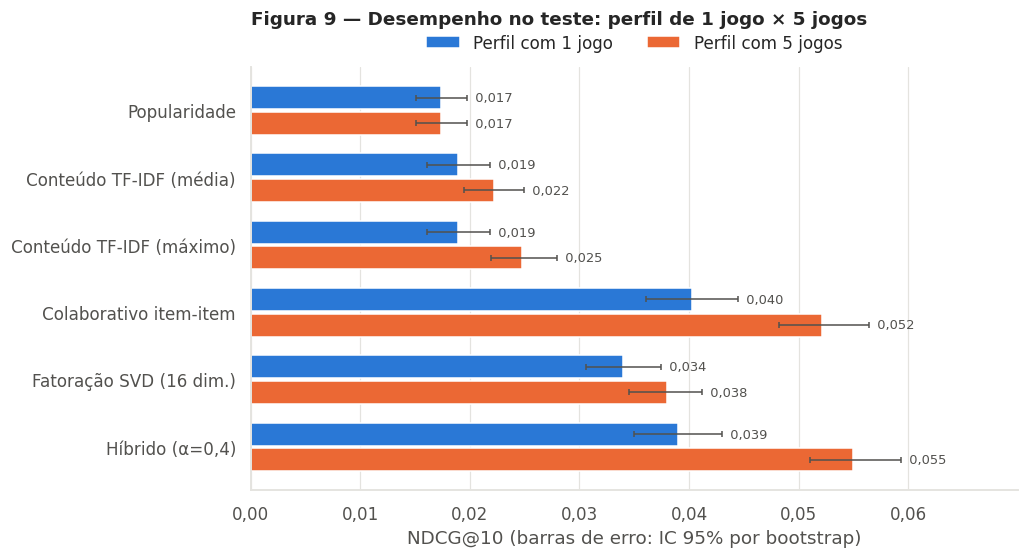

In [7]:
t = tabela.copy()
t["ic_inf"] = t["ndcg_ic95"].map(lambda x: x[0])
t["ic_sup"] = t["ndcg_ic95"].map(lambda x: x[1])
nomes = [mdl.nome for mdl in modelos]
y = np.arange(len(nomes))
altura = 0.38

fig, ax = plt.subplots(figsize=(9, 5))
for i, (perfil, cor) in enumerate([("1 jogo", g.AZUL), ("5 jogos", g.LARANJA)]):
    d = t[t["perfil"] == perfil].set_index("modelo").loc[nomes]
    pos = y + (i - 0.5) * altura
    ax.barh(pos, d["ndcg@10"], height=altura - 0.04, color=cor, label=f"Perfil com {perfil}")
    ax.errorbar(d["ndcg@10"], pos, xerr=[d["ndcg@10"] - d["ic_inf"], d["ic_sup"] - d["ndcg@10"]],
                fmt="none", ecolor=g.TEXTO_SECUNDARIO, elinewidth=1, capsize=2)
    for v, sup, yy in zip(d["ndcg@10"], d["ic_sup"], pos):
        ax.text(sup, yy, "  " + g.br(v, "{:.3f}"), va="center", fontsize=8.5, color=g.TEXTO_SECUNDARIO)
ax.set_yticks(y, nomes)
ax.invert_yaxis()
ax.margins(x=0.18)
ax.set_xlabel("NDCG@10 (barras de erro: IC 95% por bootstrap)")
g.eixo_br(ax, "x", "{:.2f}")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
ax.set_title("Figura 9 — Desempenho no teste: perfil de 1 jogo × 5 jogos", pad=28)
ax.grid(axis="y", visible=False)
g.salvar(fig, "fig09_ndcg_1x5_modelos")
plt.show()

### Teste estatístico pareado (Wilcoxon) — a diferença entre 1 e 5 jogos é significativa?

In [8]:
testes = []
for modelo in modelos:
    if modelo is pop:
        continue  # popularidade ignora o perfil: 1 e 5 jogos são idênticos
    a = por_usuario[(modelo.nome, 1)]["ndcg"]
    b_ = por_usuario[(modelo.nome, 5)]["ndcg"]
    testes.append({"modelo": modelo.nome, "ndcg_1_jogo": a.mean(), "ndcg_5_jogos": b_.mean(),
                   **av.comparar_pareado(a, b_)})
testes = pd.DataFrame(testes)
testes["significativo_5%"] = testes["p_valor"] < 0.05
testes.to_csv(config.RESULTADOS / "teste_wilcoxon_1x5.csv", index=False)
testes

,modelo,ndcg_1_jogo,ndcg_5_jogos,diferenca_media,estatistica,p_valor,significativo_5%
0,Conteúdo TF-IDF (média),0.0189,0.0222,0.0032,"34,280.5000",0.0706,False
1,Conteúdo TF-IDF (máximo),0.0189,0.0247,0.0058,"25,776.0000",0.0002,True
2,Colaborativo item-item,0.0403,0.0521,0.0118,"138,827.0000",0.0000,True
3,Fatoração SVD (16 dim.),0.0340,0.0380,0.0040,"98,299.5000",0.0171,True
4,"Híbrido (α=0,4)",0.0390,0.0550,0.0160,"127,128.0000",0.0000,True


### Comparação entre modelos (perfil de 5 jogos) — as diferenças são reais?
Mesmo teste pareado, agora entre modelos. Responde, por exemplo, se o híbrido é de fato melhor que o item-item
puro ou se a diferença está dentro do ruído. Para dar escala aos números absolutos, calculamos também o HitRate@10
esperado de uma recomendação **aleatória**.

In [9]:
pares = [(hibrido, item_item), (item_item, svd), (item_item, tfidf_max), (item_item, pop), (tfidf_max, pop)]
comp = []
for melhor, outro in pares:
    a = por_usuario[(outro.nome, 5)]["ndcg"]
    b_ = por_usuario[(melhor.nome, 5)]["ndcg"]
    comp.append({"modelo_A": melhor.nome, "modelo_B": outro.nome,
                 "ndcg_A": b_.mean(), "ndcg_B": a.mean(), **av.comparar_pareado(a, b_)})
comp = pd.DataFrame(comp)
comp["significativo_5%"] = comp["p_valor"] < 0.05
comp.to_csv(config.RESULTADOS / "teste_wilcoxon_modelos.csv", index=False)

n_alvo = casos_teste["alvo"].map(len).mean()
hr_aleatorio = 1 - (1 - n_alvo / indice.n) ** config.K
print(f"HitRate@10 esperado de uma recomendação aleatória: {hr_aleatorio:.3%} "
      f"({n_alvo:.1f} jogos escondidos por usuário, catálogo de {indice.n:,} jogos)")
comp

HitRate@10 esperado de uma recomendação aleatória: 0.194% (3.0 jogos escondidos por usuário, catálogo de 15,451 jogos)


,modelo_A,modelo_B,ndcg_A,ndcg_B,diferenca_media,estatistica,p_valor,significativo_5%
0,"Híbrido (α=0,4)",Colaborativo item-item,0.0550,0.0521,0.0029,"75,193.0000",0.0122,True
1,Colaborativo item-item,Fatoração SVD (16 dim.),0.0521,0.0380,0.0141,"143,453.0000",0.0000,True
2,Colaborativo item-item,Conteúdo TF-IDF (máximo),0.0521,0.0247,0.0274,"64,620.0000",0.0000,True
3,Colaborativo item-item,Popularidade,0.0521,0.0174,0.0347,"60,646.5000",0.0000,True
4,Conteúdo TF-IDF (máximo),Popularidade,0.0247,0.0174,0.0074,"58,930.0000",0.0006,True


### Quantos jogos recentes usar? (curva de 1 a 5 jogos no perfil)

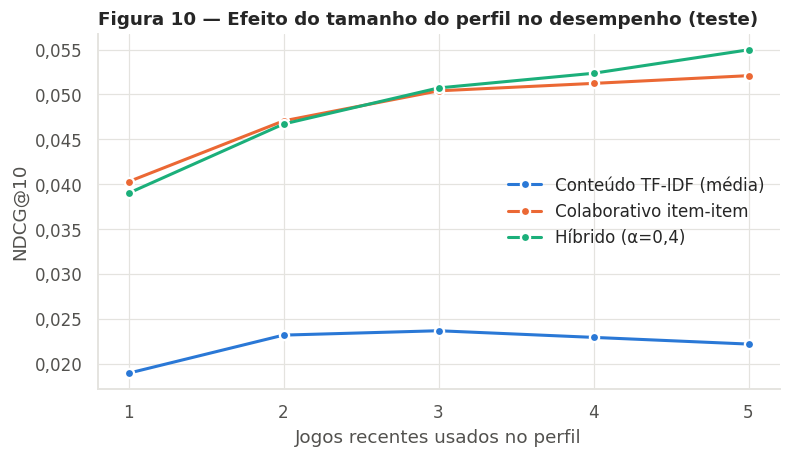

In [10]:
curva = []
for modelo in [tfidf_media, item_item, hibrido]:
    for tam in range(1, 6):
        _, r = av.avaliar(modelo, casos_teste, tamanho_perfil=tam)
        curva.append({"modelo": modelo.nome, "jogos_no_perfil": tam, "ndcg@10": r["ndcg@10"]})
curva = pd.DataFrame(curva)
curva.to_csv(config.RESULTADOS / "curva_tamanho_perfil.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.2))
for cor, (nome, d) in zip(g.CORES, curva.groupby("modelo", sort=False)):
    ax.plot(d["jogos_no_perfil"], d["ndcg@10"], color=cor, marker="o", markersize=6,
            markeredgecolor="white", markeredgewidth=1.5, label=nome)
ax.set_xticks(range(1, 6))
ax.set_xlim(0.8, 5.2)
ax.set_xlabel("Jogos recentes usados no perfil")
ax.set_ylabel("NDCG@10")
g.eixo_br(ax, "y", "{:.3f}")
ax.set_title("Figura 10 — Efeito do tamanho do perfil no desempenho (teste)")
ax.legend(loc="best")
g.salvar(fig, "fig10_curva_tamanho_perfil")
plt.show()

### Filtro de qualidade: ajuda ou atrapalha?

In [11]:
abl = []
for modelo in [tfidf_media, item_item, hibrido]:
    for filtro in (False, True):
        _, r = av.avaliar(modelo, casos_teste, tamanho_perfil=5, filtro_qualidade=filtro, popularidade=pop.scores)
        abl.append(r)
ablacao = pd.DataFrame(abl)[["modelo", "filtro_qualidade", "precision@10", "recall@10",
                             "hit_rate@10", "ndcg@10", "cobertura_catalogo", "popularidade_media_recs"]]
ablacao.to_csv(config.RESULTADOS / "ablacao_filtro_qualidade.csv", index=False)
ablacao

,modelo,filtro_qualidade,precision@10,recall@10,hit_rate@10,ndcg@10,cobertura_catalogo,popularidade_media_recs
0,Conteúdo TF-IDF (média),False,0.0087,0.0290,0.0800,0.0222,0.3358,809.3555
1,Conteúdo TF-IDF (média),True,0.0093,0.0309,0.0851,0.0235,0.2982,906.8626
2,Colaborativo item-item,False,0.0208,0.0692,0.1866,0.0521,0.2923,"2,610.6685"
3,Colaborativo item-item,True,0.0208,0.0692,0.1869,0.0521,0.2640,"2,653.1970"
4,"Híbrido (α=0,4)",False,0.0218,0.0728,0.1943,0.0550,0.2972,"2,427.8896"
5,"Híbrido (α=0,4)",True,0.0218,0.0727,0.1943,0.0551,0.2683,"2,471.6873"


## Avaliação qualitativa (proposta do seminário: notas 0, 1 e 2)
Perfis montados à mão com jogos conhecidos. O CSV exportado tem uma coluna `nota_relevancia` em branco para o grupo
preencher (2 = relevante, 1 = parcialmente relevante, 0 = irrelevante). Jogos que não existirem no catálogo são ignorados.

In [12]:
perfis_teste = {
    "Seminário (FPS + RPG + Souls)": ["Call of Duty", "Cyberpunk 2077", "ELDEN RING", "Counter-Strike", "Red Dead Redemption 2"],
    "Indie / relaxante": ["Stardew Valley", "Terraria", "Hades", "Hollow Knight", "Celeste"],
    "Estratégia": ["Civilization VI", "Total War", "Crusader Kings", "Stellaris", "Age of Empires"],
}

def resolver(nomes):
    ids = []
    for nome in nomes:
        achados = indice.buscar_por_nome(nome)
        if len(achados):
            ids.append(int(achados.iloc[0]["app_id"]))
        else:
            print(f"  aviso: '{nome}' não encontrado no catálogo")
    return ids

linhas = []
for perfil_nome, nomes_jogos in perfis_teste.items():
    ids = resolver(nomes_jogos)
    if not ids:
        continue
    for tam in (1, 5):
        entrada = ids[-tam:]
        recs_q = hibrido.recomendar(entrada, k=10, filtro_qualidade=True)
        for pos_, linha in enumerate(recs_q.itertuples(), 1):
            linhas.append({"perfil": perfil_nome, "jogos_no_perfil": tam,
                           "entrada": " | ".join(indice.catalogo.set_index("app_id").loc[entrada, "nome"]),
                           "posicao": pos_, "recomendado": linha.nome, "score": round(linha.score, 4),
                           "nota_relevancia": ""})
qualitativa = pd.DataFrame(linhas)
qualitativa.to_csv(config.RESULTADOS / "avaliacao_qualitativa_para_preencher.csv", index=False)
qualitativa.head(20)

,perfil,jogos_no_perfil,entrada,posicao,recomendado,score,nota_relevancia
0,Seminário (FPS + RPG + Souls),1,Red Dead Redemption 2,1,Cyberpunk 2077,0.6659,
1,Seminário (FPS + RPG + Souls),1,Red Dead Redemption 2,2,Grand Theft Auto V,0.5806,
2,Seminário (FPS + RPG + Souls),1,Red Dead Redemption 2,3,The Witcher® 3: Wild Hunt,0.5770,
3,Seminário (FPS + RPG + Souls),1,Red Dead Redemption 2,4,Mafia: Definitive Edition,0.5745,
4,Seminário (FPS + RPG + Souls),1,Red Dead Redemption 2,5,Metro Exodus,0.5335,
5,Seminário (FPS + RPG + Souls),1,Red Dead Redemption 2,6,Far Cry® 5,0.5166,
6,Seminário (FPS + RPG + Souls),1,Red Dead Redemption 2,7,Fallout 4,0.5097,
7,Seminário (FPS + RPG + Souls),1,Red Dead Redemption 2,8,DOOM Eternal,0.5037,
8,Seminário (FPS + RPG + Souls),1,Red Dead Redemption 2,9,Assassin's Creed® Odyssey,0.4873,
9,Seminário (FPS + RPG + Souls),1,Red Dead Redemption 2,10,Grand Theft Auto IV: The Complete Edition,0.4865,


## Salvando o modelo final para a API (CRISP-DM — etapa 6, Implantação)

In [13]:
joblib.dump({"indice": indice, "modelo": hibrido, "alpha": melhor_alpha, "svd_dimensoes": melhor_d},
            config.MODELOS / "recomendador.joblib", compress=3)
resumo_modelagem = {"melhor_alpha": melhor_alpha, "svd_dimensoes": melhor_d,
                    "tempos_treino_s": tempos, "densidade_matriz": densidade,
                    "usuarios_validacao": len(validacao), "usuarios_teste": len(casos_teste)}
with open(config.RESULTADOS / "resumo_modelagem.json", "w", encoding="utf-8") as f:
    json.dump(resumo_modelagem, f, ensure_ascii=False, indent=2, default=float)
resumo_modelagem

{'melhor_alpha': 0.4,
 'svd_dimensoes': 16,
 'tempos_treino_s': {'Popularidade': 0.06369757652282715,
  'Conteúdo TF-IDF (média)': 0.2510840892791748,
  'Conteúdo TF-IDF (máximo)': 0.24623489379882812,
  'Colaborativo item-item': 5.992024898529053,
  'Fatoração SVD': 0.8390789031982422},
 'densidade_matriz': 0.0008827750653077408,
 'usuarios_validacao': 1500,
 'usuarios_teste': 3500}